# 00 · Entorno, mercados y referencias

Antes de entrenar nada, este notebook responde a lo que condiciona el diseño de DQN y A3C. Cada sección plantea una pregunta, la responde con una figura y termina con lo que hay que hacer con esa respuesta.

| § | Pregunta | Respuesta corta |
|---|---|---|
| 1 | ¿Qué hace exactamente el entorno? | La suma de recompensas no es lo que gana el agente: la diferencia crece con la volatilidad |
| 2 | ¿Cómo son los mercados? | El mercado 1 tiene cinco veces más ruido que el resto |
| 3 | ¿Qué escala ve la red? | Sin normalizar, la tendencia es diminuta frente a la posición |
| 4 | ¿Hay señal que aprender? | Sí en los mercados 1 y 3; no en el 2; en el 4 no con este estado |
| 5 | ¿Bastan 200 series de test? | Sí, pero diferencias de pocos puntos siguen siendo ruido |
| 6 | ¿Qué hay que batir? | Reglas de dos líneas que ya superan a los tabulares del Taller 1 |
| 7 | ¿Cuánto podemos entrenar? | Un barrido grande con DQN cabe en horas, siempre que se entrene cada varios pasos |

Todo el análisis usa series de entrenamiento, salvo donde se indica. Los hiperparámetros de las reglas se eligen en validación y el test se usa una sola vez.

In [1]:
import sys
import time
from pathlib import Path

sys.path.insert(0, str(Path.cwd() if Path.cwd().name == "notebooks" else Path.cwd() / "notebooks"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from common.agents import RULES, baseline_agents, evaluate_reference
from common.env import SimpleTradingEnv
from common.markets import MARKETS, make_prices
from common.protocol import N_STEPS, N_TEST, N_VAL, RESULT_COLUMNS, run_episode, run_grid, save_results
from common.style import AGENT_COLORS, MARKET_COLORS, MARKET_LABELS, POSITION_COLORS, savefig, setup

setup()

MERCADOS = list(MARKETS)
ACCIONES = {0: "vender", 1: "mantener", 2: "comprar"}
COMISION = 0.001

# Muestra de entrenamiento para el análisis: nada de esto toca validación ni test
N_SERIES = 50
PRECIOS = {m: np.array([make_prices(m, N_STEPS, s) for s in range(N_SERIES)]) for m in MERCADOS}


def tendencia(precios):
    """Lo mismo que calcula el entorno: desviación del último precio respecto a la media de 6."""
    w = np.lib.stride_tricks.sliding_window_view(precios, 6, axis=1)
    return (w[..., -1] - w.mean(axis=-1)) / w.mean(axis=-1)


RETORNOS = {m: np.diff(p, axis=1) / p[:, :-1] for m, p in PRECIOS.items()}
# TENDENCIAS[m][:, i] se observa justo antes de RETORNOS_SIG[m][:, i]
TENDENCIAS = {m: tendencia(p)[:, :-1] for m, p in PRECIOS.items()}
RETORNOS_SIG = {m: r[:, 5:] for m, r in RETORNOS.items()}

## 1. ¿Qué hace exactamente el entorno?

La observación es `[tendencia, posición]`: la desviación del último precio respecto a la media de los últimos 6, y si se tiene el activo. Cada paso se elige vender, mantener o comprar, siempre con todo el capital y al último precio conocido.

La tabla sigue un guion de 10 acciones en una serie real del browniano. **En verde, las operaciones que sí se ejecutan; en rojo, las órdenes que no hacen nada.**

In [2]:
precios = make_prices("browniano", N_STEPS, seed=0)
env = SimpleTradingEnv(precios)
obs, _ = env.reset()
filas = []
for paso, accion in enumerate([1, 2, 1, 2, 1, 0, 0, 1, 2, 0], start=1):
    posicion, precio = env.position, env.prices[env.current_step]
    tiene_efecto = (accion == 2 and posicion == 0) or (accion == 0 and posicion == 1)
    tend = obs[0]
    obs, r, _, _, info = env.step(accion)
    filas.append({"paso": paso, "tendencia": tend, "posición antes": posicion, "acción": ACCIONES[accion],
                  "¿tiene efecto?": "sí" if tiene_efecto else ("—" if accion == 1 else "NO"),
                  "precio de ejecución": precio, "precio siguiente": env.prices[env.current_step],
                  "recompensa": r, "balance": info["balance"]})
tabla = pd.DataFrame(filas)


def resaltar(fila):
    if fila["¿tiene efecto?"] == "NO":
        return ["background-color: #FBE3E4"] * len(fila)
    if fila["¿tiene efecto?"] == "sí":
        return ["background-color: #E3F4EA"] * len(fila)
    return [""] * len(fila)


display(tabla.style.apply(resaltar, axis=1).hide(axis="index").format({
    "tendencia": "{:+.4f}", "precio de ejecución": "{:.2f}", "precio siguiente": "{:.2f}",
    "recompensa": "{:+.4f}", "balance": "{:.2f}"}))
print(f"Decisiones por episodio con {N_STEPS} precios: {N_STEPS - 1 - 5}")

paso,tendencia,posición antes,acción,¿tiene efecto?,precio de ejecución,precio siguiente,recompensa,balance
1,+0.0385,0,mantener,—,113.30,115.46,+0.0000,1000.00
2,+0.0394,0,comprar,sí,115.46,115.10,-0.0041,995.88
3,+0.0198,1,mantener,—,115.10,114.85,-0.0022,993.73
4,+0.0051,1,comprar,NO,114.85,115.79,+0.0081,1001.82
5,+0.0068,1,mantener,—,115.79,116.11,+0.0028,1004.61
6,+0.0088,1,vender,sí,116.11,119.53,-0.0010,1003.61
7,+0.0291,0,vender,NO,119.53,121.35,+0.0000,1003.61
8,+0.0361,0,mantener,—,121.35,121.63,+0.0000,1003.61
9,+0.0289,0,comprar,sí,121.63,122.70,+0.0078,1011.44
10,+0.0266,1,vender,sí,122.70,123.51,-0.0010,1010.43


Decisiones por episodio con 500 precios: 494


**Qué se ve en la tabla:**

- **Comprar con el activo o vender sin él no hace nada** (pasos 4 y 7): no se paga comisión y equivalen a mantener. La red tiene dos acciones que hacen lo mismo en cada estado, y eso no debe confundirse con exploración.
- **Al comprar se cobra ya la variación del paso** (paso 9: +0,0088 de subida menos 0,001 de comisión = +0,0078), porque se compra al precio anterior.
- **Al vender se paga la comisión y se pierde la subida siguiente** (paso 6: el precio sube de 116,11 a 119,53 y la recompensa es −0,001).

La recompensa suma retornos simples, pero el balance se compone. ¿Importa esa diferencia?

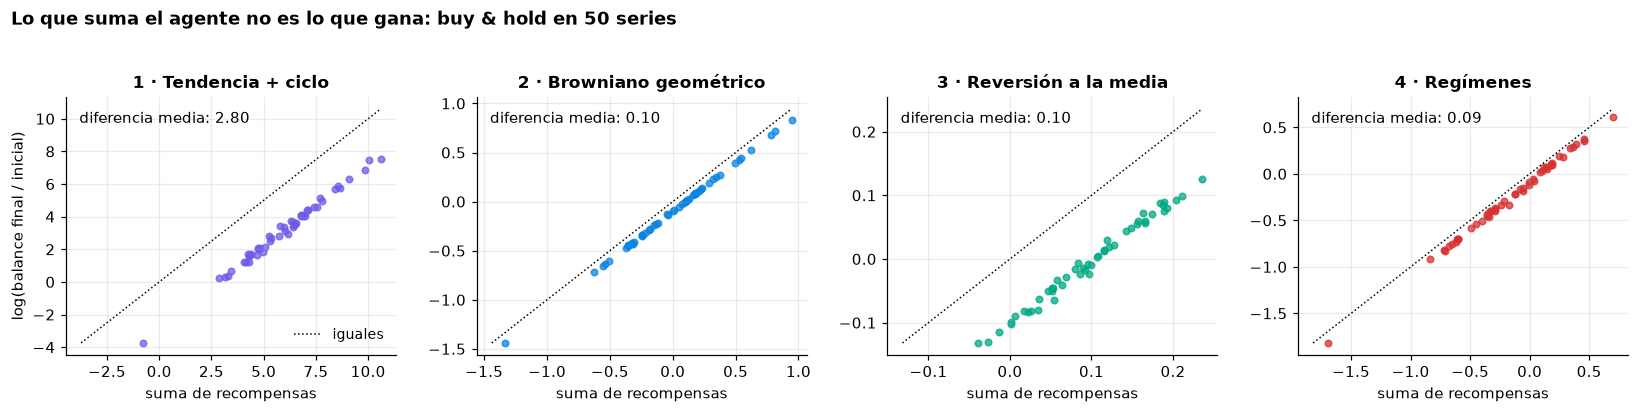

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, m in zip(axes, MERCADOS):
    p = PRECIOS[m]
    suma_r = (p[:, 6:] / p[:, 5:-1] - 1).sum(axis=1) - COMISION
    log_balance = np.log(0.999 * p[:, -1] / p[:, 5])
    ax.scatter(suma_r, log_balance, s=18, color=MARKET_COLORS[m], alpha=0.75)
    lim = [min(suma_r.min(), log_balance.min()), max(suma_r.max(), log_balance.max())]
    ax.plot(lim, lim, color="black", ls=":", lw=1, label="iguales")
    ax.set_title(MARKET_LABELS[m])
    ax.set_xlabel("suma de recompensas")
    ax.text(0.04, 0.9, f"diferencia media: {(suma_r - log_balance).mean():.2f}", transform=ax.transAxes, fontsize=9.5)
axes[0].set_ylabel("log(balance final / inicial)")
axes[0].legend(loc="lower right")
fig.suptitle("Lo que suma el agente no es lo que gana: buy & hold en 50 series", x=0.01, ha="left", weight="bold", y=1.03)
fig.tight_layout()
savefig(fig, "00_recompensa_vs_balance");
plt.show()

**Qué se ve:** todos los puntos caen por debajo de la diagonal. Maximizar la suma de recompensas no es maximizar el capital final: la suma sobreestima lo que se gana en $T\sigma^2/2$, con $T=494$ pasos y $\sigma$ el ruido por paso. Eso da unos 0,10 en los mercados 2-4 y **2,8 en el mercado 1**, justo lo que marca la figura.

**Qué hacer:** la métrica de los informes es siempre el balance, no la recompensa de entrenamiento. Una curva de recompensa que sube no garantiza más capital, sobre todo en el mercado 1. Probar `log(balance)` como recompensa es una extensión natural para el 03.

## 2. ¿Cómo son los mercados?

Los cuatro generadores del enunciado. Arriba, 30 series de cada uno con su mediana en color; abajo, la distribución de sus retornos por paso. La línea punteada marca el precio inicial.

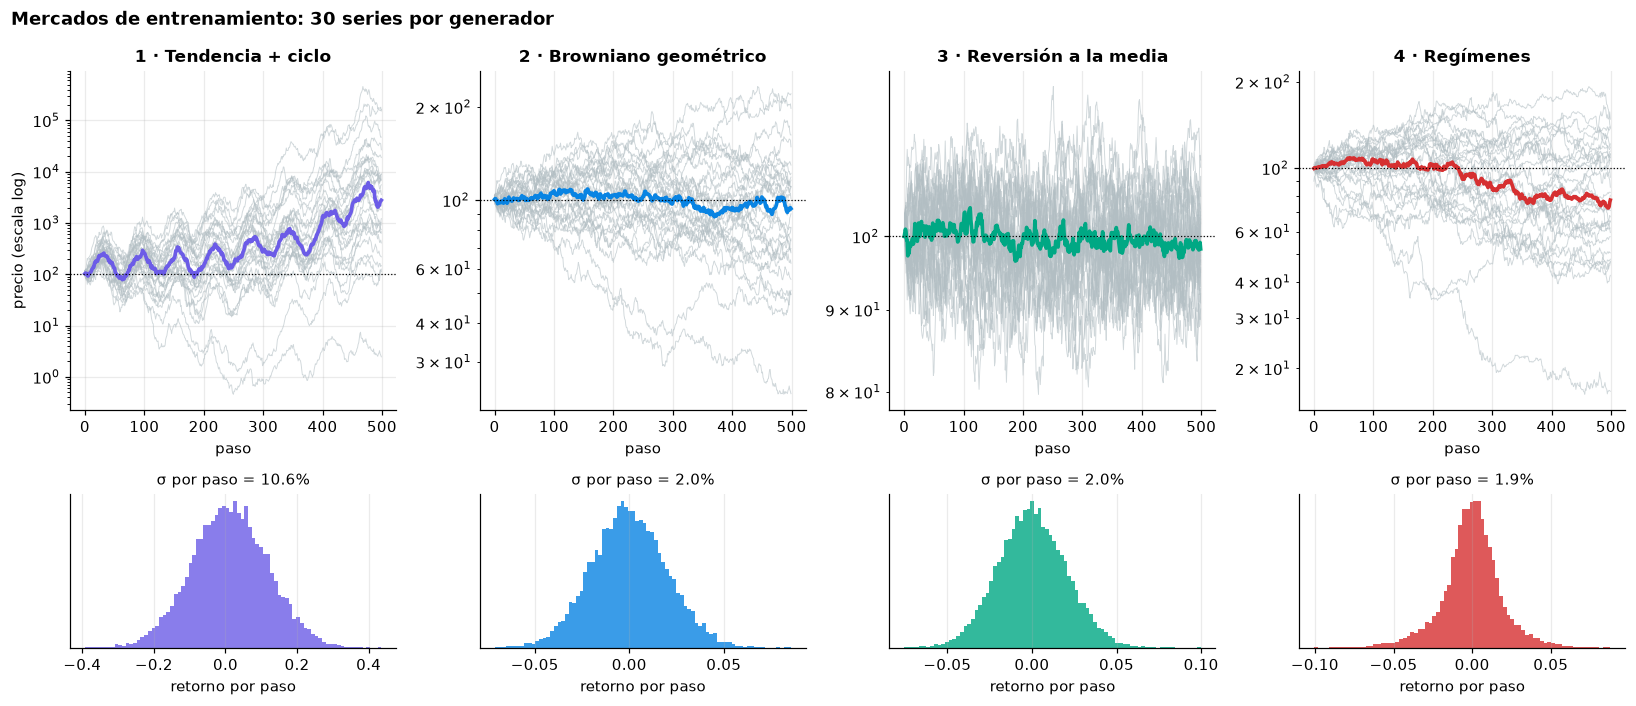

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5), gridspec_kw={"height_ratios": [2.2, 1]})
for j, m in enumerate(MERCADOS):
    series = PRECIOS[m][:30]
    ax = axes[0, j]
    ax.plot(series.T, color="#B2BEC3", lw=0.6, alpha=0.6)
    ax.plot(np.median(series, axis=0), color=MARKET_COLORS[m], lw=2.4, label="mediana")
    ax.axhline(100, color="black", ls=":", lw=0.8)
    ax.set_yscale("log")
    ax.set_title(MARKET_LABELS[m])
    ax.set_xlabel("paso")
    if j == 0:
        ax.set_ylabel("precio (escala log)")
    retornos = RETORNOS[m][:30]
    ax = axes[1, j]
    ax.hist(retornos.ravel(), bins=80, color=MARKET_COLORS[m], alpha=0.8)
    ax.set_xlabel("retorno por paso")
    ax.set_yticks([])
    ax.locator_params(axis="x", nbins=5)
    ax.set_title(f"σ por paso = {retornos.std():.1%}", fontsize=9.5, weight="normal")
fig.suptitle("Mercados de entrenamiento: 30 series por generador", x=0.01, ha="left", weight="bold")
fig.tight_layout()
savefig(fig, "00_mercados");
plt.show()

**Qué se ve:**

- **Mercado 1:** sube con un ciclo claro, pero con un ruido del 10,6 % por paso, unas cinco veces el del resto. Algunas series multiplican por miles y otras casi desaparecen.
- **Mercado 2:** se dispersa sin dirección. Es el control: no hay nada que aprender.
- **Mercado 3:** siempre vuelve a 100. Es el único con un rango acotado.
- **Mercado 4:** cae en mediana, con cambios bruscos entre fases. Sus retornos tienen colas más anchas, por la mezcla de regímenes.

**Qué hacer:** usar la mediana y no la media para comparar. En el mercado 1, la media de buy & hold es de +19 925 % y su mediana, +3 262 %.

## 3. ¿Qué escala ve la red?

En el Taller 1 la tendencia se partía en cuantiles y su escala no importaba. Una red recibe el número tal cual, y entrena con la magnitud de la recompensa. Esto aporta la evidencia para decidir D-1.1.

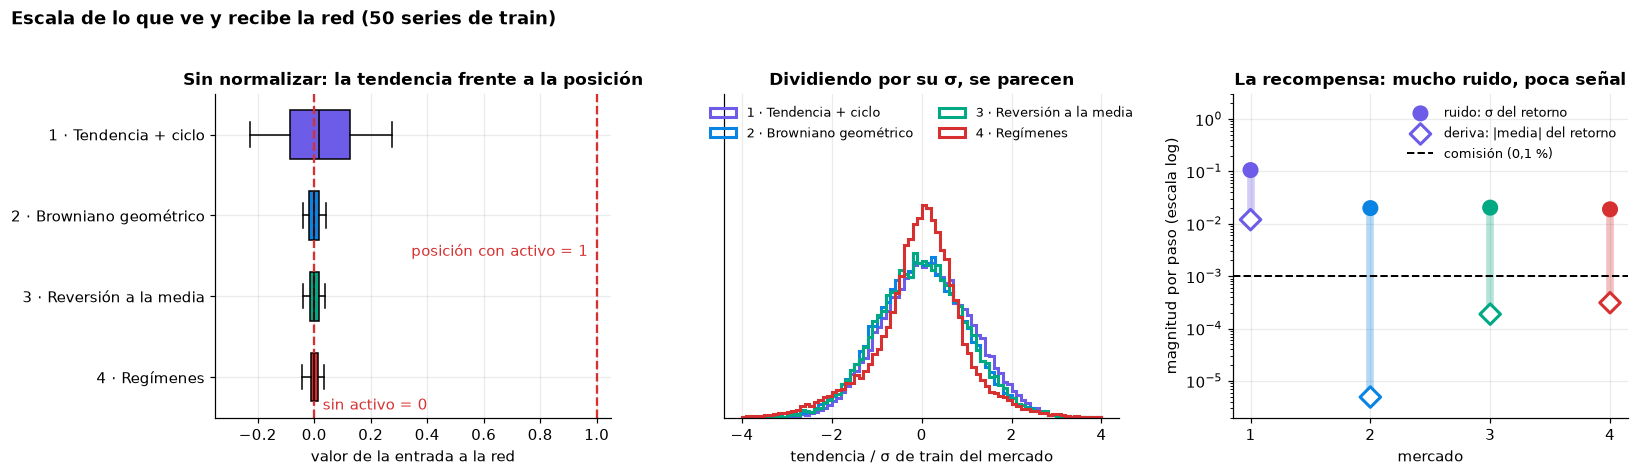

,tendencia p5,tendencia p95,σ tendencia,media retorno,σ retorno,ruido / comisión
1 · Tendencia + ciclo,-0.227,+0.276,0.153,+0.01202,0.106,106
2 · Browniano geométrico,-0.040,+0.040,0.025,-0.00000,0.020,20
3 · Reversión a la media,-0.039,+0.040,0.024,+0.00019,0.020,20
4 · Regímenes,-0.044,+0.036,0.024,-0.00031,0.019,19


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

ax = axes[0]
datos = [TENDENCIAS[m].ravel() for m in MERCADOS]
caja = ax.boxplot(datos, orientation="horizontal", whis=(5, 95), showfliers=False, patch_artist=True, widths=0.6,
                  medianprops={"color": "black"})
for parche, m in zip(caja["boxes"], MERCADOS):
    parche.set_facecolor(MARKET_COLORS[m])
ax.set_yticks(range(1, 5), [MARKET_LABELS[m] for m in MERCADOS])
ax.invert_yaxis()
ax.axvline(1, color="#D63031", ls="--", lw=1.5)
ax.text(0.97, 2.5, "posición con activo = 1", color="#D63031", ha="right", fontsize=9.5)
ax.text(0.03, 4.4, "sin activo = 0", color="#D63031", fontsize=9.5)
ax.axvline(0, color="#D63031", ls="--", lw=1.5)
ax.set_xlim(-0.35, 1.05)
ax.set_xlabel("valor de la entrada a la red")
ax.set_title("Sin normalizar: la tendencia frente a la posición")

ax = axes[1]
for m in MERCADOS:
    x = TENDENCIAS[m].ravel()
    ax.hist(x / x.std(), bins=80, range=(-4, 4), density=True, histtype="step", lw=2, color=MARKET_COLORS[m],
            label=MARKET_LABELS[m])
ax.set_xlabel("tendencia / σ de train del mercado")
ax.set_yticks([])
ax.set_ylim(0, ax.get_ylim()[1] * 1.45)
ax.legend(fontsize=8.5, ncols=2, loc="upper center")
ax.set_title("Dividiendo por su σ, se parecen")

ax = axes[2]
x = np.arange(4)
sigma = [RETORNOS[m].std() for m in MERCADOS]
media = [abs(RETORNOS[m].mean()) for m in MERCADOS]
for i, m in enumerate(MERCADOS):
    ax.vlines(i, media[i], sigma[i], color=MARKET_COLORS[m], lw=5, alpha=0.3)
ax.scatter(x, sigma, s=90, marker="o", color=[MARKET_COLORS[m] for m in MERCADOS], label="ruido: σ del retorno", zorder=3)
ax.scatter(x, media, s=90, marker="D", facecolors="white", edgecolors=[MARKET_COLORS[m] for m in MERCADOS], lw=2,
           label="deriva: |media| del retorno", zorder=3)
ax.axhline(COMISION, color="black", ls="--", lw=1.3, label="comisión (0,1 %)")
ax.set_yscale("log")
ax.set_xticks(x, ["1", "2", "3", "4"])
ax.set_xlabel("mercado")
ax.set_ylabel("magnitud por paso (escala log)")
ax.set_ylim(2e-6, 3)
ax.legend(fontsize=8.5, loc="upper right", ncols=1)
ax.set_title("La recompensa: mucho ruido, poca señal")
fig.suptitle("Escala de lo que ve y recibe la red (50 series de train)", x=0.01, ha="left", weight="bold", y=1.02)
fig.tight_layout()
savefig(fig, "00_escala_entradas");
plt.show()

resumen = pd.DataFrame({MARKET_LABELS[m]: {
    "tendencia p5": np.percentile(TENDENCIAS[m], 5), "tendencia p95": np.percentile(TENDENCIAS[m], 95),
    "σ tendencia": TENDENCIAS[m].std(), "media retorno": RETORNOS[m].mean(), "σ retorno": RETORNOS[m].std(),
    "ruido / comisión": RETORNOS[m].std() / COMISION,
} for m in MERCADOS}).T
display(resumen.style.format({"ruido / comisión": "{:.0f}", "media retorno": "{:+.5f}", "tendencia p5": "{:+.3f}",
                              "tendencia p95": "{:+.3f}", "σ tendencia": "{:.3f}", "σ retorno": "{:.3f}"}))

**Qué se ve:**

- **Izquierda:** en los mercados 2-4, el 90 % de las tendencias cae en ±0,04, mientras que la otra entrada vale 0 o 1. Al empezar, la red apenas puede ver la tendencia.
- **Centro:** dividiendo por la σ de train de cada mercado, las cuatro distribuciones se parecen. Basta una constante por mercado, calculada solo con train.
- **Derecha:** el ruido es entre 19 y 106 veces la comisión. Salvo en el mercado 1, la deriva queda por debajo de la comisión: un paso aislado casi no informa. La escala absoluta (≈0,02) también es pequeña para un objetivo de regresión, por lo que el error de la red será diminuto.

**Qué hacer (D-1.1, ya decidida; ver `docs/DECISIONES.md`):**

1. Dividir la tendencia por su σ de train: 0,153 en el mercado 1 y unos 0,024 en los demás.
2. Multiplicar la recompensa por una constante por mercado, también fijada en train. No cambia la política óptima y deja la tasa de aprendizaje y la entropía en un rango comparable entre mercados.
3. Una prueba con un DQN mínimo lo respalda: en reversión a la media, sin nada se obtiene 0 % y con las dos cosas, +10,4 %, aunque con solo 3 semillas (`results/00_grid_normalizacion.csv`). `train_scales(mercado)` da las constantes.

## 4. ¿Hay señal que aprender?

Se ordenan todos los pasos por la tendencia observada, se parten en diez grupos iguales y se mide el retorno medio del paso siguiente. Una barra solo importa si sale de la banda naranja (la comisión) y su error no cruza el cero.

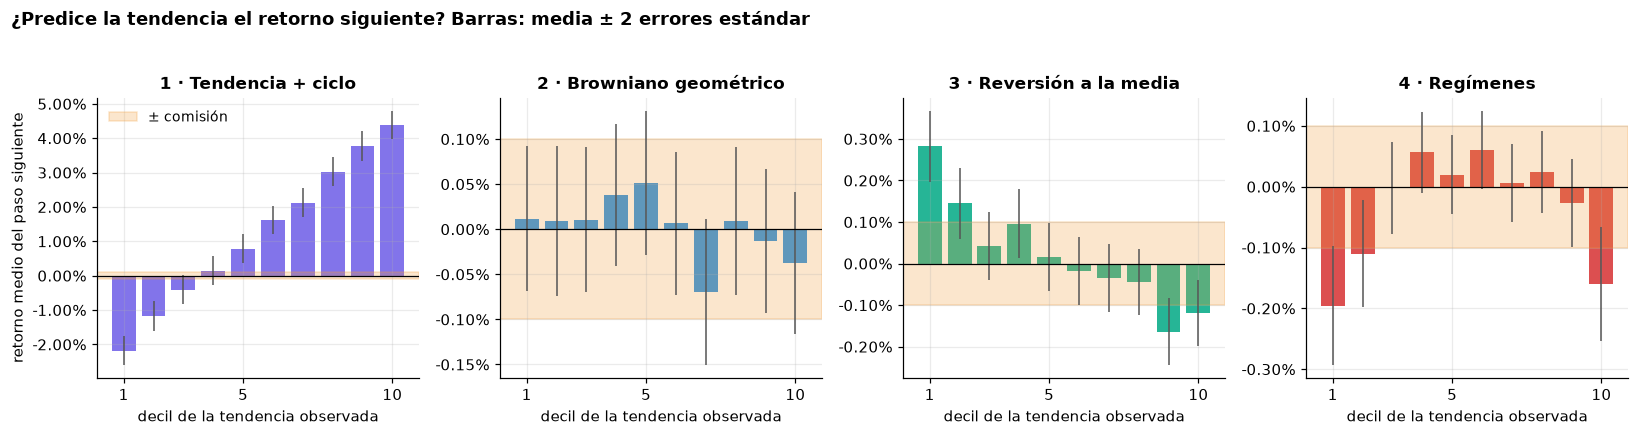

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, m in zip(axes, MERCADOS):
    x, y = TENDENCIAS[m].ravel(), RETORNOS_SIG[m].ravel()
    grupo = np.minimum((pd.Series(x).rank(pct=True).to_numpy() * 10).astype(int), 9)
    medias = np.array([y[grupo == g].mean() for g in range(10)])
    errores = np.array([2 * y[grupo == g].std() / np.sqrt((grupo == g).sum()) for g in range(10)])
    ax.bar(range(1, 11), medias, yerr=errores, color=MARKET_COLORS[m], alpha=0.85, error_kw={"lw": 1, "ecolor": "#555"})
    ax.axhspan(-COMISION, COMISION, color="#F29D38", alpha=0.25, label="± comisión")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks([1, 5, 10])
    ax.set_xlabel("decil de la tendencia observada")
    ax.set_title(MARKET_LABELS[m])
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.2%}"))
axes[0].set_ylabel("retorno medio del paso siguiente")
axes[0].legend(loc="upper left")
fig.suptitle("¿Predice la tendencia el retorno siguiente? Barras: media ± 2 errores estándar", x=0.01, ha="left", weight="bold", y=1.03)
fig.tight_layout()
savefig(fig, "00_senal_por_decil");
plt.show()

**Qué se ve:**

- **Mercado 1:** señal muy clara y creciente, de −2,2 % a +4,4 % por paso, muy por encima de la comisión. Conviene seguir la tendencia.
- **Mercado 2:** nada se distingue de cero y todo cabe en la banda. **Si una red gana aquí de forma sistemática, está sobreajustando.**
- **Mercado 3:** relación inversa, más pequeña: tras caídas fuertes el precio sube (+0,28 %) y tras subidas fuertes baja (−0,16 %). Solo los extremos superan la comisión, y una operación completa paga dos.
- **Mercado 4:** no es monótono. Los dos extremos son negativos: los movimientos grandes, en cualquier sentido, delatan el régimen bajista. Una regla lineal no puede usar esto; **una red sí podría**, aunque en el centro la ganancia (≈0,05 %) no paga la comisión. Es una hipótesis que merece probarse.

Dos señales más, mirando más lejos y fuera del estado:

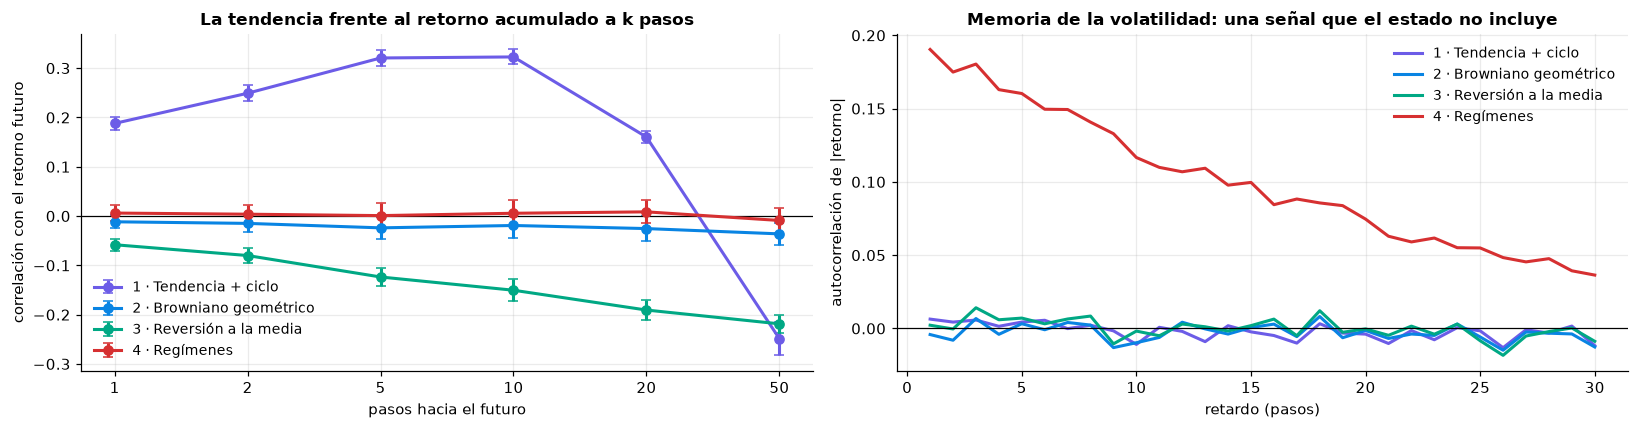

In [7]:
HORIZONTES = [1, 2, 5, 10, 20, 50]


def corr_por_serie(a, b):
    a, b = a - a.mean(axis=1, keepdims=True), b - b.mean(axis=1, keepdims=True)
    return (a * b).sum(axis=1) / np.sqrt((a**2).sum(axis=1) * (b**2).sum(axis=1))


fig, axes = plt.subplots(1, 2, figsize=(15, 4))
ax = axes[0]
for m in MERCADOS:
    p = PRECIOS[m]
    medias, errores = [], []
    for k in HORIZONTES:
        futuro = p[:, 5 + k:] / p[:, 5:-k] - 1
        c = corr_por_serie(tendencia(p)[:, :futuro.shape[1]], futuro)
        medias.append(c.mean())
        errores.append(2 * c.std() / np.sqrt(len(c)))
    ax.errorbar(range(len(HORIZONTES)), medias, yerr=errores, marker="o", lw=2, capsize=3, color=MARKET_COLORS[m], label=MARKET_LABELS[m])
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(range(len(HORIZONTES)), HORIZONTES)
ax.set_xlabel("pasos hacia el futuro")
ax.set_ylabel("correlación con el retorno futuro")
ax.legend(fontsize=9)
ax.set_title("La tendencia frente al retorno acumulado a k pasos")

ax = axes[1]
retardos = range(1, 31)
for m in MERCADOS:
    v = np.abs(RETORNOS[m])
    ax.plot(retardos, [corr_por_serie(v[:, :-k], v[:, k:]).mean() for k in retardos], lw=2, color=MARKET_COLORS[m], label=MARKET_LABELS[m])
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("retardo (pasos)")
ax.set_ylabel("autocorrelación de |retorno|")
ax.legend(fontsize=9)
ax.set_title("Memoria de la volatilidad: una señal que el estado no incluye")
fig.tight_layout()
savefig(fig, "00_memoria");
plt.show()

**Qué se ve:**

- **Izquierda:** la señal del mercado 1 alcanza su máximo a 5-10 pasos y **cambia de signo hacia los 50**, porque el ciclo dura unos 63 pasos. La del mercado 3 se refuerza con el horizonte. En ambos, un agente que mire más allá de un paso tiene ventaja, lo que afecta a la elección de γ y de `t_max`.
- **Derecha:** solo el mercado 4 tiene memoria en la volatilidad. Explica por qué en el Taller 1 añadir volatilidad al estado fue lo único que mejoró este mercado (de 0 % a +7,8 %).

**Estrategia esperada en cada mercado** (ejercicio 2 del enunciado), con el mejor tabular del Taller 1 como referencia:

| Mercado | Qué dice la señal | Qué debería aprender | Q-Learning en el Taller 1 |
|---|---|---|---|
| 1 · Tendencia + ciclo | Fuerte, a favor de la tendencia | Seguir la tendencia | x502 |
| 2 · Browniano | Ninguna | No operar | 0 % |
| 3 · Reversión | Moderada, inversa | Comprar tras caídas extremas y vender tras subidas extremas | +27,0 % |
| 4 · Regímenes | Débil, y sobre todo en la volatilidad | No operar con este estado | 0 % |

**Qué hacer:** comparar lo que aprenda cada red con esta tabla. Si difiere, hay que entender por qué.

## 5. ¿Bastan 200 series de test?

Se calcula la mediana de buy & hold añadiendo series una a una, con 1 000 series nuevas que no pertenecen a train, validación ni test. El protocolo, heredado del Taller 1 para poder comparar (D-0.1):

| Conjunto | Semillas | Series | Uso |
|---|---|---|---|
| Train | `semilla × 10 000 + episodio` | Una por episodio | Entrenar |
| Validación | desde 50 000 | 100 | Elegir hiperparámetros |
| Test | desde 100 000 | 200 | Resultado final, una sola vez |

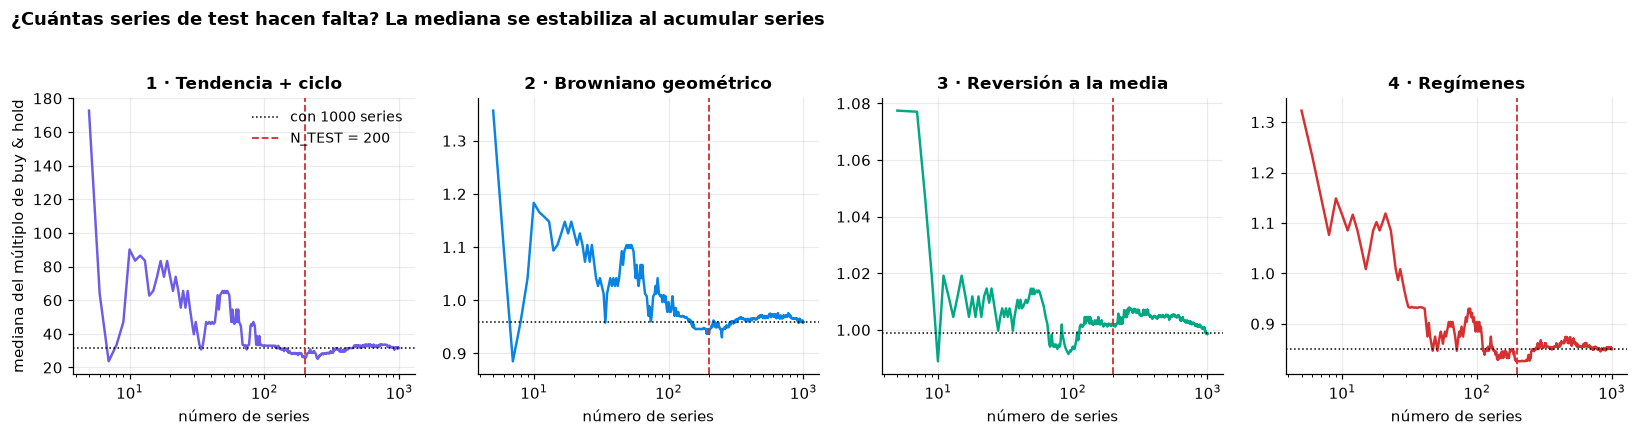

Error estándar de la mediana del múltiplo (bootstrap):


,n = 25,n = 50,n = 100,n = 200,n = 400,n = 800
1 · Tendencia + ciclo,22.112,12.692,8.551,5.711,3.580,2.730
2 · Browniano geométrico,0.104,0.076,0.049,0.032,0.023,0.014
3 · Reversión a la media,0.019,0.013,0.009,0.007,0.004,0.003
4 · Regímenes,0.106,0.070,0.054,0.037,0.027,0.019


In [8]:
N_MAX = 1000
SEMILLA_ESTABILIDAD = 200_000  # fuera de train, validación y test
TAMANOS = [25, 50, 100, 200, 400, 800]
rng = np.random.default_rng(0)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
filas = {}
for ax, m in zip(axes, MERCADOS):
    p = np.array([make_prices(m, N_STEPS, SEMILLA_ESTABILIDAD + i) for i in range(N_MAX)])
    multiplo = 0.999 * p[:, -1] / p[:, 5]  # buy & hold, sin depender de ningún agente
    log_m = np.log(multiplo)
    corrida = [np.median(log_m[:n]) for n in range(5, N_MAX + 1)]
    ax.plot(range(5, N_MAX + 1), np.exp(corrida), color=MARKET_COLORS[m], lw=1.6)
    ax.axhline(np.median(multiplo), color="black", ls=":", lw=1, label=f"con {N_MAX} series")
    ax.axvline(N_TEST, color="#D63031", ls="--", lw=1.2, label="N_TEST = 200")
    ax.set_xscale("log")
    ax.set_xlabel("número de series")
    ax.set_title(MARKET_LABELS[m])
    filas[MARKET_LABELS[m]] = {f"n = {n}": np.std([np.median(rng.choice(multiplo, n)) for _ in range(500)]) for n in TAMANOS}
axes[0].set_ylabel("mediana del múltiplo de buy & hold")
axes[0].legend(fontsize=9)
fig.suptitle("¿Cuántas series de test hacen falta? La mediana se estabiliza al acumular series", x=0.01, ha="left", weight="bold", y=1.03)
fig.tight_layout()
savefig(fig, "00_estabilidad_test");
plt.show()

print("Error estándar de la mediana del múltiplo (bootstrap):")
display(pd.DataFrame(filas).T.style.format("{:.3f}"))

**Qué se ve:** con menos de 100 series, la mediana oscila mucho: en el browniano pasa de 1,18 a 0,89. A partir de 200 ya se mueve poco alrededor del valor con 1 000 series.

**Qué hacer:** mantener 200 series, y no dar por buena una diferencia pequeña. El error estándar con 200 series es de unos 3-4 puntos en los mercados 2 y 4, y de 0,7 en el 3. Como orientación, **menos de unos 7 puntos en los mercados 2 y 4, o de 1,5 en el 3, no prueba nada**. Comparar sobre las mismas series afina algo más, porque el ruido del mercado se comparte.

## 6. ¿Qué hay que batir?

Además del aleatorio y de buy & hold, que pide el enunciado, se añaden tres referencias:

- **No operar:** conserva el capital. En tres mercados ya bate a buy & hold.
- **Regla de tendencia:** entra si la tendencia supera un umbral y sale si cae por debajo de menos ese umbral.
- **Regla de reversión:** lo contrario.

Son políticas fijas de dos líneas que no aprenden. Su único parámetro, el umbral, se elige en validación entre 0; 0,5; 1 y 1,5 veces la σ de la tendencia. **Si DQN o A3C no las superan, no han aprendido nada que no diera ya una regla simple.**

In [9]:
UMBRALES_K = [0.0, 0.5, 1.0, 1.5]  # en múltiplos de la σ de la tendencia en train
sigma_train = {m: float(TENDENCIAS[m].std()) for m in MERCADOS}

# 1) Validación: elegir el umbral de cada regla en cada mercado
configs = [{"agente": r, "mercado": m, "k": k, "umbral": k * sigma_train[m], "split": "val"}
           for r in RULES for m in MERCADOS for k in UMBRALES_K]
validacion, _ = run_grid(configs, evaluate_reference, "00_grid_reglas", n_jobs=3)
elegidas = validacion.loc[validacion.groupby(["agente", "mercado"]).retorno_mediana.idxmax()]

# 2) Test: una sola evaluación de baselines y reglas elegidas
finales = [{"agente": a, "mercado": m, "umbral": 0.0, "split": "test"} for a in baseline_agents() for m in MERCADOS]
finales += [{"agente": f.agente, "mercado": f.mercado, "umbral": f.umbral, "split": "test"} for f in elegidas.itertuples()]
test, retornos_test = run_grid(finales, evaluate_reference, "00_grid_referencias", n_jobs=3)
referencias = save_results(test[RESULT_COLUMNS].to_dict("records"), "00_baselines")
RETORNO = {(f.agente, f.mercado): retornos_test[f.id] for f in test.itertuples()}
AGENTES = list(baseline_agents()) + list(RULES)

umbrales = elegidas.assign(mercado=elegidas.mercado.map(MARKET_LABELS)).pivot(index="mercado", columns="agente", values="k")
print("Umbral elegido en validación (en múltiplos de la σ de la tendencia):")
display(umbrales.loc[[MARKET_LABELS[m] for m in MERCADOS]])

Umbral elegido en validación (en múltiplos de la σ de la tendencia):


agente,regla_reversion,regla_tendencia
mercado,,
1 · Tendencia + ciclo,1.5,0.5
2 · Browniano geométrico,1.0,1.5
3 · Reversión a la media,1.5,0.5
4 · Regímenes,1.5,1.5


mercado,1 · Tendencia + ciclo,2 · Browniano geométrico,3 · Reversión a la media,4 · Regímenes
agente,,,,
aleatorio,+330.4%,-19.4%,-17.2%,-22.0%
buy_hold,x33.6,-3.5%,-0.3%,-12.5%
no_operar,+0.0%,+0.0%,+0.0%,+0.0%
regla_tendencia,x630.4,-4.4%,-22.3%,-10.5%
regla_reversion,-50.1%,-4.8%,+29.2%,-10.6%


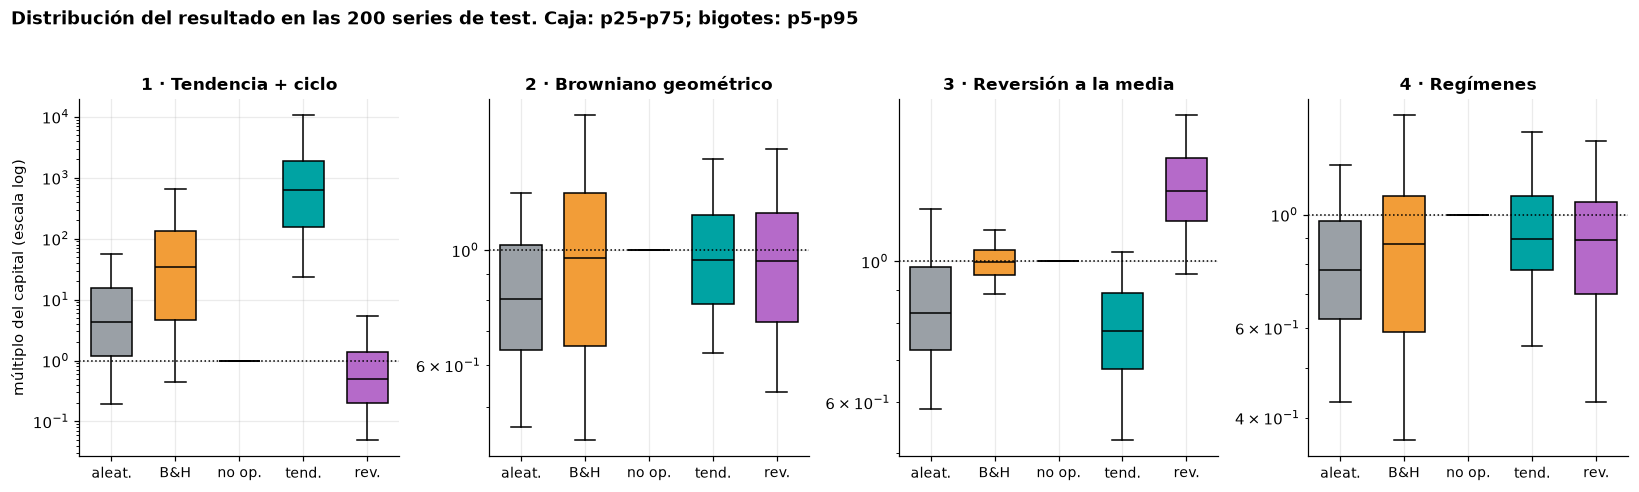

In [10]:
def formato(r):
    return f"x{1 + r:.1f}" if r >= 5 else f"{r:+.1%}"


tabla = referencias.pivot(index="agente", columns="mercado", values="retorno_mediana").loc[AGENTES, MERCADOS]


def mejor(col):
    return ["background-color: #E3F4EA; font-weight: bold" if v == col.max() else "" for v in col]


display(tabla.style.apply(mejor).format(formato).format_index(lambda m: MARKET_LABELS[m], axis=1)
        .set_caption("Mediana del retorno en las 200 series de test. En verde, la mejor de cada mercado."))

fig, axes = plt.subplots(1, 4, figsize=(15, 4.3))
for ax, m in zip(axes, MERCADOS):
    datos = [1 + RETORNO[a, m] for a in AGENTES]
    caja = ax.boxplot(datos, whis=(5, 95), showfliers=False, patch_artist=True, widths=0.65, medianprops={"color": "black"})
    for parche, a in zip(caja["boxes"], AGENTES):
        parche.set_facecolor(AGENT_COLORS[a])
    ax.axhline(1, color="black", ls=":", lw=1)
    ax.set_yscale("log")
    ax.set_xticks(range(1, len(AGENTES) + 1), ["aleat.", "B&H", "no op.", "tend.", "rev."], fontsize=9)
    ax.set_title(MARKET_LABELS[m])
axes[0].set_ylabel("múltiplo del capital (escala log)")
fig.suptitle("Distribución del resultado en las 200 series de test. Caja: p25-p75; bigotes: p5-p95", x=0.01, ha="left", weight="bold", y=1.03)
fig.tight_layout()
savefig(fig, "00_referencias_distribucion");
plt.show()

**Qué se ve:**

- **Las reglas superan a los tabulares del Taller 1:** x630 frente a x502 en el mercado 1, y +29,2 % frente a +27,0 % en el 3. Es el listón real para DQN y A3C. Los tabulares ganan a los baselines del enunciado, pero aprenden casi lo mismo que estas reglas.
- **Cada regla solo funciona en su mercado.** La de reversión pierde un −50,1 % en el mercado 1 y la de tendencia, un −22,3 % en el 3.
- **En los mercados 2 y 4 nada bate a no operar.** Las reglas, buy & hold y el aleatorio pierden en mediana. Las diferencias entre las reglas y buy & hold en el mercado 2 (−4,4 % y −4,8 % frente a −3,5 %) son ruido, según el §5.
- **El aleatorio pierde por las comisiones:** unas 165 operaciones por episodio. En el mercado 1, aun así, multiplica el capital: la tendencia es tan fuerte que estar dentro la mitad del tiempo basta.
- **Las cajas muestran lo que la mediana esconde:** en el mercado 1, buy & hold va de menos de x1 a más de x600 entre los percentiles 5 y 95.

El riesgo y la actividad de cada referencia:

In [11]:
orden = pd.MultiIndex.from_product([MERCADOS, AGENTES], names=["mercado", "agente"])
metricas = referencias.set_index(["mercado", "agente"]).loc[orden, ["retorno_mediana", "retorno_medio", "std", "sharpe", "max_drawdown", "n_trades"]]
metricas = metricas.rename(index=MARKET_LABELS, level="mercado")
display(metricas.style.format({"retorno_mediana": "{:+.1%}", "retorno_medio": "{:+.1%}", "std": "{:.1%}", "sharpe": "{:+.3f}",
                               "max_drawdown": "{:.1%}", "n_trades": "{:.1f}"}).background_gradient(
    subset=["sharpe"], cmap="RdYlGn", vmin=-0.2, vmax=0.2))

**Qué se ve:** además de ganar más, la regla de tendencia reduce la caída máxima del mercado 1 (60,6 % frente a 89,5 % de buy & hold) y casi duplica su Sharpe. La de reversión reduce la del mercado 3 (19,1 % frente a 25,9 %). **La validación también puede engañar:** en el mercado 2 eligió el umbral de reversión por un −0,1 %, y en test salió −4,8 %, porque ahí no hay señal.

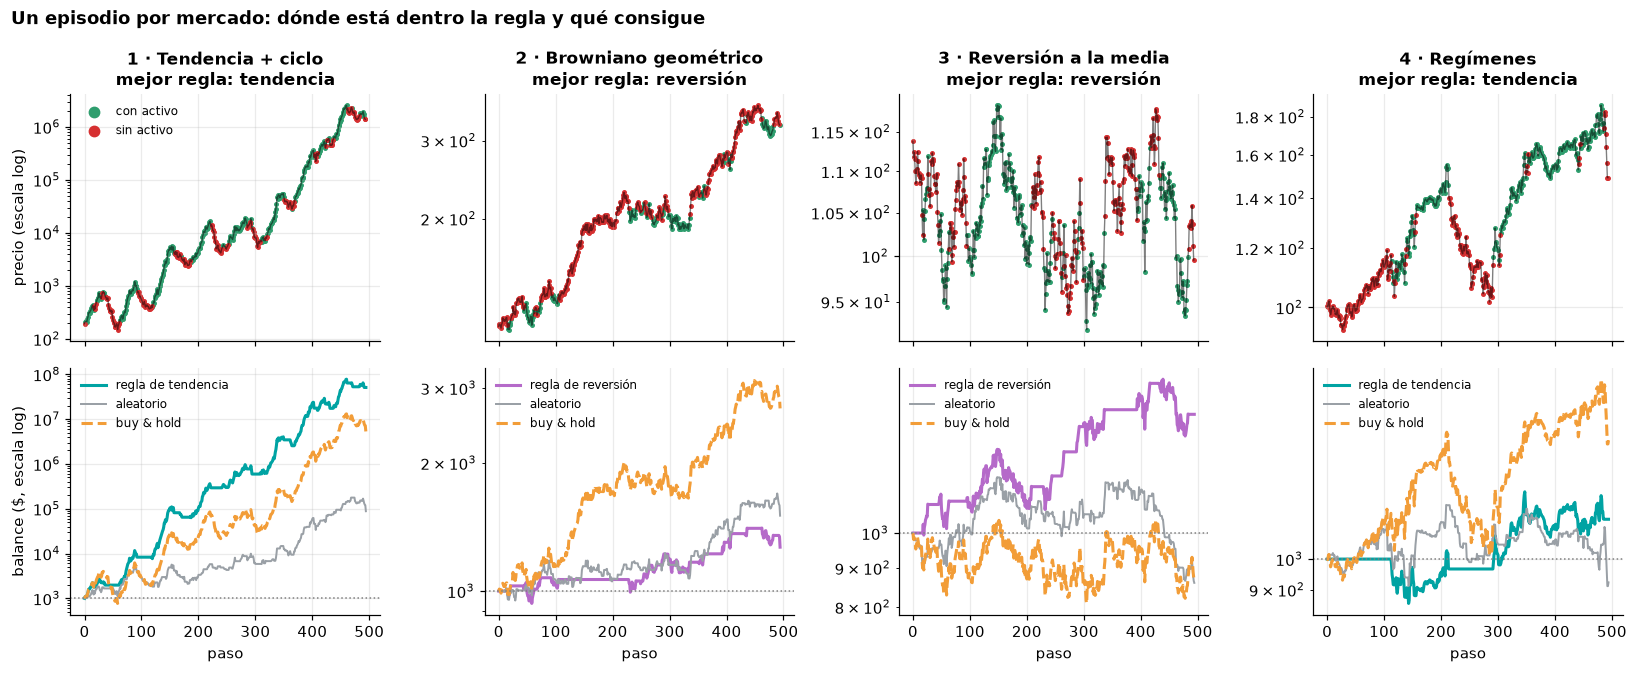

In [12]:
SEMILLA_EJEMPLO = 50_000  # primera serie de validación
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharex=True, gridspec_kw={"height_ratios": [1, 1]})
for j, m in enumerate(MERCADOS):
    fila = elegidas[elegidas.mercado == m].sort_values("retorno_mediana").iloc[-1]
    agente = RULES[fila.agente](fila.umbral)
    precios = make_prices(m, N_STEPS, SEMILLA_EJEMPLO)
    _, balance, _, posicion = run_episode(SimpleTradingEnv(precios), agente)
    validos = precios[5:-1]
    ax = axes[0, j]
    ax.plot(validos, color="black", lw=0.9, alpha=0.5)
    ax.set_yscale("log")
    ax.scatter(np.flatnonzero(posicion == 1), validos[posicion == 1], s=5, color=POSITION_COLORS[1], label="con activo")
    ax.scatter(np.flatnonzero(posicion == 0), validos[posicion == 0], s=5, color=POSITION_COLORS[0], label="sin activo")
    nombre = "tendencia" if fila.agente == "regla_tendencia" else "reversión"
    ax.set_title(f"{MARKET_LABELS[m]}\nmejor regla: {nombre}")
    ax = axes[1, j]
    ax.plot(balance, color=AGENT_COLORS[fila.agente], lw=2, label=f"regla de {nombre}")
    ax.plot(run_episode(SimpleTradingEnv(precios), baseline_agents()["aleatorio"])[1], color=AGENT_COLORS["aleatorio"], lw=1.3, label="aleatorio")
    ax.plot(run_episode(SimpleTradingEnv(precios), baseline_agents()["buy_hold"])[1], color=AGENT_COLORS["buy_hold"], lw=2, ls="--", label="buy & hold")
    ax.axhline(1000, color="gray", ls=":", lw=1)
    ax.set_yscale("log")
    ax.set_xlabel("paso")
    ax.legend(fontsize=8)
axes[0, 0].set_ylabel("precio (escala log)")
axes[0, 0].legend(fontsize=8, markerscale=3)
axes[1, 0].set_ylabel("balance ($, escala log)")
fig.suptitle("Un episodio por mercado: dónde está dentro la regla y qué consigue", x=0.01, ha="left", weight="bold")
fig.tight_layout()
savefig(fig, "00_episodios");
plt.show()

**Qué se ve:** en verde, cuándo está dentro la mejor regla de cada mercado. En el 1 captura las subidas y evita parte de las caídas. En el 3 compra en los valles y vende en los picos, y por eso su balance sube a escalones mientras buy & hold no avanza. En el 2 y el 4 opera sin ventaja: en esta serie, que sube mucho, buy & hold gana por azar. **Un episodio no prueba nada**, y por eso los resultados se miden sobre 200 series.

## 7. ¿Cuánto podemos entrenar?

Aún no hay DQN ni A3C, pero sí se puede medir lo que costarán sus piezas: el entorno real y una red como la de partida (100 neuronas), en un solo núcleo. El coste por episodio se estima sumándolas; **es una estimación de este equipo (AMD Ryzen 5 3600: 6 núcleos físicos y 12 lógicos, sin GPU), y cada uno debería volver a ejecutarla en el suyo.**

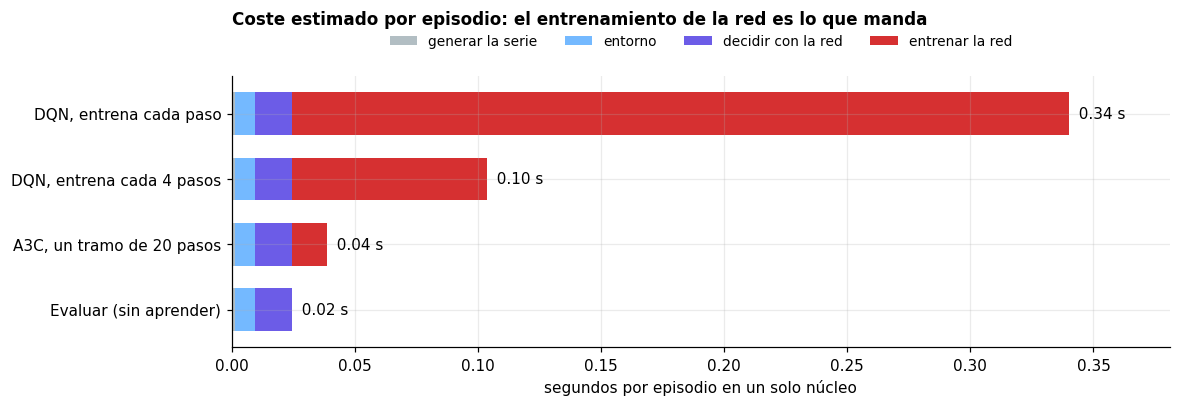

Horas estimadas con 11 procesos en DQN y 3 workers en A3C (el entrenamiento más la evaluación de 300 series):


,"DQN, entrena cada paso","DQN, entrena cada 4 pasos","A3C, un tramo de 20 pasos"
"Final: 5 semillas × 4 mercados, 500 ep.",0.2 h,0.1 h,0.1 h
"Barrido pequeño: 8 config. × 3 semillas × 4 mercados, 300 ep.",0.5 h,0.2 h,0.2 h
"Barrido grande: 32 config. × 3 semillas × 4 mercados, 500 ep.",3.4 h,1.1 h,1.1 h


In [13]:
def medir(funcion, repeticiones):
    inicio = time.perf_counter()
    for _ in range(repeticiones):
        funcion()
    return (time.perf_counter() - inicio) / repeticiones


torch.set_num_threads(1)  # como en cada proceso de run_grid o de A3C
red = torch.nn.Sequential(torch.nn.Linear(2, 100), torch.nn.ReLU(), torch.nn.Linear(100, 3))
optimizador = torch.optim.Adam(red.parameters(), 1e-3)
estado = torch.zeros(1, 2)
mb_x, mb_y = torch.zeros(128, 2), torch.zeros(128, 3)
tramo_x, tramo_y = torch.zeros(20, 2), torch.zeros(20, 3)


def inferencia():
    with torch.no_grad():
        red(estado)


def entrenar(x, y):
    optimizador.zero_grad()
    ((red(x) - y) ** 2).mean().backward()
    optimizador.step()


def episodio_entorno():
    env = SimpleTradingEnv(PRECIOS["browniano"][0])
    env.reset()
    terminado = False
    while not terminado:
        terminado = env.step(1)[2]


PASOS = N_STEPS - 1 - 5
t_serie = medir(lambda: make_prices("regimenes", N_STEPS, 1), 20)
t_entorno = medir(episodio_entorno, 10)
t_red = medir(inferencia, 1000) * PASOS
t_batch = medir(lambda: entrenar(mb_x, mb_y), 200)
t_tramo = medir(lambda: entrenar(tramo_x, tramo_y), 200)

desglose = pd.DataFrame({
    "DQN, entrena cada paso": [t_serie, t_entorno, t_red, t_batch * PASOS],
    "DQN, entrena cada 4 pasos": [t_serie, t_entorno, t_red, t_batch * PASOS / 4],
    "A3C, un tramo de 20 pasos": [t_serie, t_entorno, t_red, t_tramo * PASOS / 20],
    "Evaluar (sin aprender)": [t_serie, t_entorno, t_red, 0.0],
}, index=["generar la serie", "entorno", "decidir con la red", "entrenar la red"]).T

fig, ax = plt.subplots(figsize=(11, 3.2))
desglose.iloc[::-1].plot.barh(stacked=True, ax=ax, color=["#B2BEC3", "#74B9FF", "#6C5CE7", "#D63031"], width=0.65)
for i, total in enumerate(desglose.iloc[::-1].sum(axis=1)):
    ax.text(total, i, f"  {total:.2f} s", va="center", fontsize=10)
ax.set_xlabel("segundos por episodio en un solo núcleo")
ax.set_title("Coste estimado por episodio: el entrenamiento de la red es lo que manda", loc="left", pad=34)
ax.set_xlim(0, desglose.sum(axis=1).max() * 1.12)
ax.legend(fontsize=9, ncols=4, loc="upper center", bbox_to_anchor=(0.5, 1.2))
ax.set_ylabel("")
savefig(fig, "00_coste_por_episodio");
plt.show()

# Episodios por segundo frente a un solo proceso, medidos con todos a la vez en este equipo:
# compartir la CPU frena a cada proceso. 11 procesos en DQN y 3 workers en A3C (run_grid no los anida).
GANANCIA = {"DQN, entrena cada paso": 5.5, "DQN, entrena cada 4 pasos": 5.5, "A3C, un tramo de 20 pasos": 2.5}
coste = desglose.sum(axis=1)
evaluar = (N_TEST + N_VAL) * coste["Evaluar (sin aprender)"]


def horas(entrenamientos, episodios, por_episodio, ganancia):
    return entrenamientos * (episodios * por_episodio + evaluar) / ganancia / 3600


escenarios = {"Final: 5 semillas × 4 mercados, 500 ep.": (20, 500), "Barrido pequeño: 8 config. × 3 semillas × 4 mercados, 300 ep.": (96, 300),
              "Barrido grande: 32 config. × 3 semillas × 4 mercados, 500 ep.": (384, 500)}
presupuesto = pd.DataFrame({
    nombre: {col: horas(n, ep, coste[col], GANANCIA[col]) for col in ["DQN, entrena cada paso", "DQN, entrena cada 4 pasos", "A3C, un tramo de 20 pasos"]}
    for nombre, (n, ep) in escenarios.items()}).T
print(f"Horas estimadas con 11 procesos en DQN y 3 workers en A3C (el entrenamiento más la evaluación de {N_TEST + N_VAL} series):")
display(presupuesto.style.format("{:.1f} h").background_gradient(cmap="YlOrRd", vmin=0, vmax=24))

**Qué se ve:**

- **El entrenamiento de la red es lo que manda en DQN.** Hacerlo cada 4 pasos en lugar de en cada paso reduce el coste a un tercio.
- **A3C es más barato por episodio**, porque actualiza con menos frecuencia y sin memoria. Pero puede necesitar más episodios para aprender, así que los dos no se comparan solo con este número.
- **Generar la serie apenas cuenta**, de modo que usar una serie nueva por episodio no es un problema.
- **Un barrido grande con DQN cabe:** unas 3,4 h entrenando en cada paso y 1,2 h cada 4 pasos. Las ganancias de la tabla sí están medidas con los procesos compitiendo: 11 procesos rinden x5,5 y 3, x2,5.
- **Las cifras siguen siendo optimistas.** Con el entorno y la red juntos, un episodio tipo cuesta 0,135 s, un 30 % más que los 0,103 s de la suma, y aquí falta la gestión de la memoria y de la red objetivo. Tampoco incluyen el arranque de los procesos de A3C, unos 3 s por entrenamiento.

**Qué hacer:**

1. Empezar por DQN entrenando cada varios pasos, y ajustar con 2 mercados (el 1 y el 3) antes de pasar a los otros. Los barridos de DQN usan 6 procesos: con los 11 que `run_grid` lanza por defecto, el equipo se queda sin memoria.
2. Ajustar por etapas, un hiperparámetro cada vez, como en el Taller 1, y no con una rejilla completa.
3. Repartir los barridos entre los tres equipos, cada uno con su propio nombre de barrido en `run_grid`.

## 8. Conclusiones

| Hallazgo | Consecuencia para el 01 y el 02 |
|---|---|
| La tendencia es 25 veces menor que la posición y varía según el mercado | Normalizarla con la σ de train (D-1.1) |
| La recompensa es mucho ruido y poca señal | Escalarla por mercado y necesitar muchos pasos (D-1.1) |
| La suma de recompensas sobreestima el capital | Medir siempre con el balance, no con la curva de entrenamiento |
| Hay señal en los mercados 1 y 3, y ninguna en el 2 | El browniano es la prueba contra el sobreajuste |
| La señal se extiende a varios pasos | Probar γ y `t_max` altos |
| El mercado 4 no es lineal en la tendencia | Una red podría aportar algo que una regla no; probarlo |
| La memoria del mercado 4 está en la volatilidad | Extensión para el 03: ampliar el estado |
| Las reglas de dos líneas baten a los tabulares | **El listón es x630, +29,2 %, 0 % y 0 %**, no buy & hold |
| Diferencias de pocos puntos son ruido | Justificar mejoras con varias semillas y las mismas series |
| El entrenamiento de la red domina el coste | Entrenar cada varios pasos y ajustar por etapas |

Los resultados se guardan en `results/00_baselines.csv`, y el notebook 04 los lee para la tabla final.